# 04 — Target Variable Analysis (Partie 4)

| | |
|---|---|
| **Question de la partie** | *Que sait-on exactement de la variable cible, et que cela impose-t-il à la modélisation et à l'évaluation ?* |
| **Entrées** | `hai-test1`, `hai-test2` et leurs fichiers de labels (+ le nombre de lignes des fichiers `train`) |
| **Sorties** | `reports/attack_events.csv`, `reports/target_analysis.json`, figures `reports/figures/4x_*` |

> **Règle d'usage des données (anti-fuite).** Cette partie utilise les labels **de façon descriptive uniquement** : comptages, durées, calendrier. Aucun choix de modèle, de seuil ni de variable n'en découle directement. Les décisions de modélisation fondées sur les labels se prennent avec **test1 seulement** ; test2 reste réservé à l'évaluation finale.

> **Pourquoi cette partie est importante.** Dans un projet de détection d'anomalies, la cible fixe *tout* : la métrique utilisable, la taille minimale des fenêtres, la manière de découper les données, et même la faisabilité d'une approche supervisée. Elle est aussi la source d'erreurs la plus coûteuse (un alignement faux des labels invalide tous les résultats).

## 0. Configuration et chargement

In [12]:
from pathlib import Path
import json, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.patches import Patch
from scipy import stats
warnings.filterwarnings("ignore")

ROOT = Path.cwd() if (Path.cwd() / "params.yaml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
try:
    from src.data.io import find_hai_files, load_hai_csv, sensor_columns
    from src.data.prep import clean_file
    from src.data.catalog import segments, parse_summary, crosscheck
    from src.eda import target as TG
except ImportError as e:
    raise ImportError("Lance Jupyter depuis le dossier du projet (celui qui contient params.yaml et src/). Détail : " + str(e))

DATA_ROOT = ROOT / "data" / "raw"; REPORT_DIR = ROOT / "reports"; FIG_DIR = REPORT_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
VERSION_TAG, SEED = "23.05", 42
STRICT_OFFICIAL_CHECKS = True            # False UNIQUEMENT pour un test à blanc sur données de démo
WINDOWS_S = (10, 30, 60, 120, 300)       # tailles de fenêtres du cahier des charges (+ 2 fenêtres longues)
PRE_S = 300                              # baseline locale = les 5 minutes qui précèdent un événement
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.titleweight": "bold"})
PAL = {"test1": "#f0ad4e", "test2": "#8e5ea2", "normal": "#2f6fb3", "attack": "#d9534f", "ok": "#5bb4a6", "grey": "#9aa3ad"}
FINDINGS, EV = [], {}
def insight(topic, msg): FINDINGS.append((topic, msg)); print(f"💡 [{topic}] {msg}")
def savefig(name): plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()

In [13]:
FILES = find_hai_files(DATA_ROOT, VERSION_TAG, allow_unversioned=not STRICT_OFFICIAL_CHECKS)
LABEL_INFO, clean = {}, {}
for k in ("test1", "test2"):
    df = load_hai_csv(FILES[f"hai-{k}"], FILES[f"label-{k}"], LABEL_INFO); clean[k] = clean_file(df, 1, 5); del df          # labels alignés de façon vérifiée (voir §27)
TRAIN_ROWS = {k: len(pd.read_csv(FILES[f"hai-{k}"], usecols=[0])) for k in ("train1", "train2", "train3", "train4")}           # on ne lit que le timestamp
SEG = {k: segments(clean[k]) for k in clean}
print({k: v.shape for k, v in clean.items()}, "| lignes de train :", TRAIN_ROWS)

{'test1': (54000, 88), 'test2': (230400, 88)} | lignes de train : {'train1': 280800, 'train2': 291600, 'train3': 126000, 'train4': 198000}


## 27. Étude de la variable cible `attack`
**Pourquoi.** Avant de compter quoi que ce soit, il faut établir **ce qu'est** la cible : son nom, son encodage, sa granularité, d'où elle vient et comment elle a été associée aux mesures.

**Ce que l'on sait (documentation HAI).** Les attaques sont **injectées sur le banc d'essai** pendant l'expérience ; chaque seconde des fichiers de test reçoit un label. Dans les fichiers `label-test*.csv`, la colonne s'appelle `label` (elle est nommée `attack` dans certaines versions du dataset et dans ton plan).

| Élément | Valeur |
|---|---|
| Encodage | `0` = fonctionnement normal · `1` = seconde appartenant à une attaque |
| Granularité | 1 label par seconde, comme les mesures |
| Disponibilité | **uniquement** dans `test1` et `test2` ; les fichiers `train` n'ont pas de label (100 % normal) |
| Association aux mesures | fichier séparé, à aligner (voir ci-dessous) |

In [14]:
raw_lab = {k: pd.read_csv(FILES[f"label-{k}"]) for k in ("test1", "test2")}
rows = []
for k, l in raw_lab.items():
    ts, lab = l.iloc[:, 0], l.iloc[:, -1]
    rows.append({"fichier": f"label-{k}.csv", "colonnes": ", ".join(l.columns), "lignes": len(l), "timestamps_uniques": int(ts.nunique()), "lignes_par_timestamp (médiane)": int(ts.value_counts().median()),
                 "valeurs du label": sorted(lab.unique().tolist()), "type": str(lab.dtype), "valeurs_manquantes": int(lab.isna().sum())})
display(pd.DataFrame(rows).set_index("fichier"))
print("Alignement label ↔ mesures :"); display(pd.DataFrame(LABEL_INFO).T)
for k, l in raw_lab.items(): assert set(l.iloc[:, -1].unique()) <= {0, 1} and l.iloc[:, -1].notna().all(), f"label-{k} : valeurs inattendues"
print("✔ Cible binaire {0, 1}, aucune valeur manquante")

,colonnes,lignes,timestamps_uniques,lignes_par_timestamp (médiane),valeurs du label,type,valeurs_manquantes
fichier,,,,,,,
label-test1.csv,"timestamp, label",54000,54000,1,"[0, 1]",int64,0
label-test2.csv,"timestamp, label",230400,3841,60,"[0, 1]",int64,0


Alignement label ↔ mesures :


,data_rows,label_rows,label_unique_timestamps,mode,unmatched_rows,minutes,rows_per_minute_equal,labels_sorted,minute_concordance_pct
hai-test1,54000,54000,54000,jointure timestamp,0,NaN,NaN,NaN,NaN
hai-test2,230400,230400,3841,positionnel,NaN,3841,True,True,100.0


✔ Cible binaire {0, 1}, aucune valeur manquante


In [15]:
r2 = pd.DataFrame(rows).set_index("fichier").loc["label-test2.csv"]; mode2 = LABEL_INFO.get("hai-test2", {}).get("mode", "?")
insight("Cible", "La cible est binaire (0 normal / 1 attaque), à 1 Hz, sans valeur manquante, et n'existe que dans test1 et test2.")
if r2["lignes_par_timestamp (médiane)"] > 1:
    insight("Cible", f"label-test2.csv a {r2['lignes']:,} lignes mais seulement {r2['timestamps_uniques']:,} timestamps distincts ({r2['lignes_par_timestamp (médiane)']} lignes par timestamp) : ses dates sont TRONQUÉES À LA MINUTE. Une jointure sur le timestamp est donc fausse ; l'alignement correct est « {mode2} » (même nombre de lignes que les mesures, concordance à la minute vérifiée à 100 %). Ces « doublons » apparents ne sont pas une erreur de données.")

💡 [Cible] La cible est binaire (0 normal / 1 attaque), à 1 Hz, sans valeur manquante, et n'existe que dans test1 et test2.
💡 [Cible] label-test2.csv a 230,400 lignes mais seulement 3,841 timestamps distincts (60 lignes par timestamp) : ses dates sont TRONQUÉES À LA MINUTE. Une jointure sur le timestamp est donc fausse ; l'alignement correct est « positionnel » (même nombre de lignes que les mesures, concordance à la minute vérifiée à 100 %). Ces « doublons » apparents ne sont pas une erreur de données.


## 28. Répartition Normal / Attack
**Pourquoi.** Savoir quelle part du temps est en attaque, **fichier par fichier** (test1 et test2 ont des rôles différents : validation et test final) puis sur l'ensemble du dataset.

,secondes,heures,normales,en attaque,% attaque
test1,54000.0,15.0,51019.0,2981.0,5.52
test2,230400.0,64.0,221997.0,8403.0,3.65
"test1 + test2 (cumul, à titre descriptif)",284400.0,79.0,273016.0,11384.0,4.00


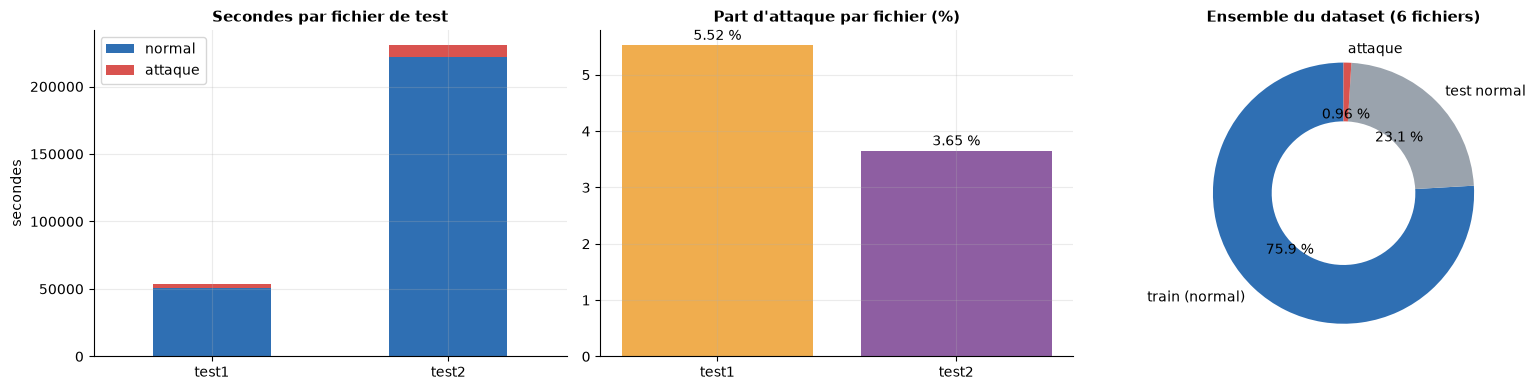

💡 [Répartition] test1 : 5.52 % d'attaque ; test2 : 3.65 %. Sur l'ensemble des 1,180,800 secondes du dataset, seulement 0.96 % sont des attaques : la classe d'intérêt est très rare.


In [16]:
comp = pd.DataFrame({k: {"secondes": len(v), "heures": round(len(v) / 3600, 1), "normales": int((v.label == 0).sum()), "en attaque": int(v.label.sum()), "% attaque": round(100 * v.label.mean(), 2)} for k, v in clean.items()}).T
comp.loc["test1 + test2 (cumul, à titre descriptif)"] = [comp.secondes.sum(), round(comp.secondes.sum() / 3600, 1), comp.normales.sum(), comp["en attaque"].sum(), round(100 * comp["en attaque"].sum() / comp.secondes.sum(), 2)]
display(comp)
n_train, n_test, n_att = sum(TRAIN_ROWS.values()), sum(len(v) for v in clean.values()), int(sum(v.label.sum() for v in clean.values())); n_all = n_train + n_test
EV["repartition"] = {"train_s": n_train, "test_s": n_test, "attack_s": n_att, "attack_pct_dataset": 100 * n_att / n_all}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
b = pd.DataFrame({k: [int((v.label == 0).sum()), int(v.label.sum())] for k, v in clean.items()}, index=["normal", "attaque"]).T; b.plot.bar(stacked=True, ax=ax[0], rot=0, color=[PAL["normal"], PAL["attack"]]); ax[0].set_title("Secondes par fichier de test"); ax[0].set_ylabel("secondes")
ax[1].bar(list(clean), [100 * v.label.mean() for v in clean.values()], color=[PAL[k] for k in clean]); ax[1].set_title("Part d'attaque par fichier (%)"); [ax[1].text(i, 100 * v.label.mean() + .1, f"{100*v.label.mean():.2f} %", ha="center") for i, v in enumerate(clean.values())]
ax[2].pie([n_train, n_test - n_att, n_att], labels=["train (normal)", "test normal", "attaque"], colors=[PAL["normal"], PAL["grey"], PAL["attack"]], autopct=lambda p: f"{p:.2f} %" if p < 5 else f"{p:.1f} %", startangle=90, wedgeprops=dict(width=.45)); ax[2].set_title("Ensemble du dataset (6 fichiers)")
savefig("40_repartition_normal_attack")
insight("Répartition", f"test1 : {comp.loc['test1','% attaque']} % d'attaque ; test2 : {comp.loc['test2','% attaque']} %. Sur l'ensemble des {n_all:,} secondes du dataset, seulement {100*n_att/n_all:.2f} % sont des attaques : la classe d'intérêt est très rare.")

## 29. Déséquilibre des classes
**Pourquoi.** Le déséquilibre décide de la **métrique** : sur des classes aussi inégales, un détecteur qui ne détecte *rien* obtient une excellente accuracy. On le démontre, puis on mesure le déséquilibre à trois niveaux : la seconde, le bloc de temps et l'événement.

,prévalence p,ratio normal : attaque,blocs d'1 h avec attaque,blocs de 10 min avec attaque,échantillons positifs (pas de 10 s),événements,précision moyenne d'un score aléatoire (≈ p)
fichier,,,,,,,
test1,0.0552,17.1 : 1,14/15,16/90,300,14,0.0552
test2,0.0365,26.4 : 1,39/64,51/384,839,38,0.0365


accuracy  précision  rappel     F1
test1 toujours « normal »      0.945        NaN     0.0  0.000
      toujours « attaque »     0.055      0.055     1.0  0.105
      au hasard (50 %)         0.500      0.055     0.5  0.099
test2 toujours « normal »      0.964        NaN     0.0  0.000
      toujours « attaque »     0.036      0.036     1.0  0.070
      au hasard (50 %)         0.500      0.036     0.5  0.068

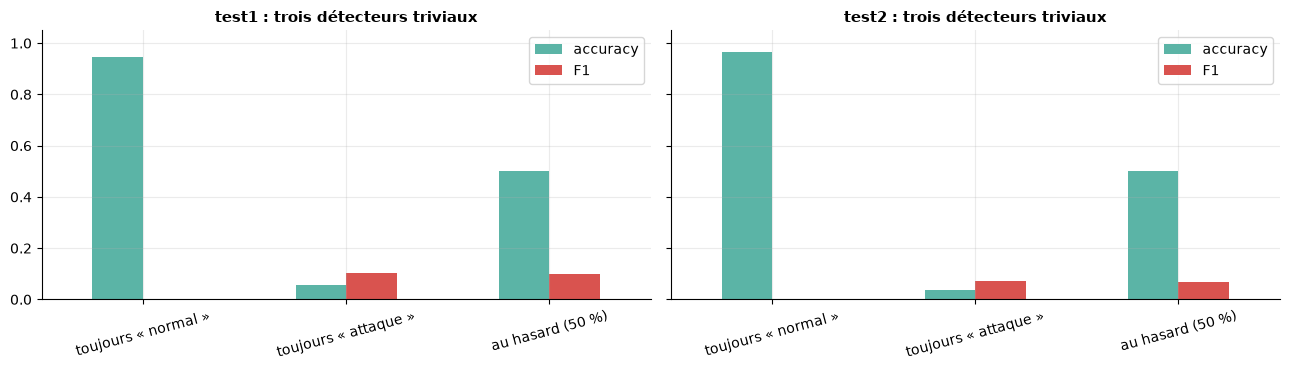

In [17]:
rows = []
for k, v in clean.items():
    p = v.label.mean(); lab = v.label.to_numpy(); n = len(lab)
    b1h = np.array([lab[a:a + 3600].any() for a in range(0, n, 3600)]); b10 = np.array([lab[a:a + 600].any() for a in range(0, n, 600)])
    rows.append({"fichier": k, "prévalence p": round(p, 4), "ratio normal : attaque": f"{(1 - p) / p:.1f} : 1", "blocs d'1 h avec attaque": f"{b1h.sum()}/{len(b1h)}", "blocs de 10 min avec attaque": f"{b10.sum()}/{len(b10)}",
                 "échantillons positifs (pas de 10 s)": int(lab[::10].sum()), "événements": len(SEG[k]), "précision moyenne d'un score aléatoire (≈ p)": round(p, 4)})
imb = pd.DataFrame(rows).set_index("fichier"); display(imb)
triv = pd.concat({k: pd.DataFrame(TG.trivial_classifiers(v.label.mean())).T for k, v in clean.items()}); display(triv.round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a, k in zip(ax, clean):
    t = triv.loc[k][["accuracy", "F1"]]; t.plot.bar(ax=a, rot=15, color=[PAL["ok"], PAL["attack"]]); a.set_title(f"{k} : trois détecteurs triviaux"); a.set_ylim(0, 1.05)
savefig("41_detecteurs_triviaux")

In [18]:
p1, p2 = clean["test1"].label.mean(), clean["test2"].label.mean()
insight("Déséquilibre", f"Rapport normal : attaque = {(1-p1)/p1:.0f} : 1 (test1) et {(1-p2)/p2:.0f} : 1 (test2). Un détecteur qui ne signale JAMAIS d'attaque obtient une accuracy de {100*(1-p1):.1f} % et {100*(1-p2):.1f} % avec un rappel nul : l'accuracy est inutilisable.")
insight("Déséquilibre", f"Un score aléatoire obtient une précision moyenne ≈ p ({p1:.3f} et {p2:.3f}) et une AUC de 0,5 : ce sont les valeurs plancher à battre. Métriques à utiliser : précision, rappel, F1, eTaPR, rappel par événement, fausses alertes par heure.")
insight("Déséquilibre", f"Au niveau des blocs de temps : {imb.loc['test1','blocs d\'1 h avec attaque']} blocs d'1 h de test1 et {imb.loc['test2','blocs d\'1 h avec attaque']} de test2 contiennent une attaque ; au niveau des événements : seulement {len(SEG['test1'])} et {len(SEG['test2'])}. Toute validation croisée doit se faire PAR BLOCS DE TEMPS ou par événement, jamais par seconde tirée au hasard.")

💡 [Déséquilibre] Rapport normal : attaque = 17 : 1 (test1) et 26 : 1 (test2). Un détecteur qui ne signale JAMAIS d'attaque obtient une accuracy de 94.5 % et 96.4 % avec un rappel nul : l'accuracy est inutilisable.
💡 [Déséquilibre] Un score aléatoire obtient une précision moyenne ≈ p (0.055 et 0.036) et une AUC de 0,5 : ce sont les valeurs plancher à battre. Métriques à utiliser : précision, rappel, F1, eTaPR, rappel par événement, fausses alertes par heure.
💡 [Déséquilibre] Au niveau des blocs de temps : 14/15 blocs d'1 h de test1 et 39/64 de test2 contiennent une attaque ; au niveau des événements : seulement 14 et 38. Toute validation croisée doit se faire PAR BLOCS DE TEMPS ou par événement, jamais par seconde tirée au hasard.


## 30. Analyse des événements d'attaque
**Pourquoi.** Une attaque est un **événement** (un segment continu de secondes à 1), pas une seconde isolée. C'est l'unité qui compte pour l'opérateur, et c'est celle de la métrique eTaPR.

**Contrôle de fiabilité.** Les auteurs de HAI fournissent `summary_label*.txt`, qui liste chaque attaque avec son début et sa fin. On vérifie que nos événements correspondent **à la seconde près** : c'est la seule preuve indépendante que l'alignement des labels est correct, y compris à l'intérieur d'une minute.

In [19]:
EV_TAB = pd.concat([SEG[k].assign(fichier=k, id=[f"{k}-A{j + 1:02d}" for j in SEG[k].index]) for k in SEG]).reset_index(drop=True)
EV_TAB["part_des_secondes_d'attaque_%"] = [round(100 * d / EV_TAB[EV_TAB.fichier == f]["durée_s"].sum(), 2) for d, f in zip(EV_TAB["durée_s"], EV_TAB.fichier)]
EV_TAB = EV_TAB[["id", "fichier", "début", "fin", "durée_s", "pause_avant_s", "part_des_secondes_d'attaque_%"]]; EV_TAB.to_csv(REPORT_DIR / "attack_events.csv", index=False)
display(EV_TAB.sort_values("durée_s", ascending=False).head(10).reset_index(drop=True))
CC = {}
for k, fn in (("test1", "summary_label1.txt"), ("test2", "summary_label2.txt")):
    path = FILES[f"hai-{k}"].parent / fn
    if not path.exists(): print(f"[{k}] {fn} absent : recoupement impossible"); continue
    summ, head = parse_summary(path); cc, extra = crosscheck(SEG[k], summ, tol_s=2); CC[k] = (head, cc, extra)
    print(f"[{k}] recoupement : {int(cc['ok'].sum())}/{len(cc)} attaques concordent à ±2 s (écart max début {cc.start_diff_s.abs().max():.0f} s, fin {cc.end_diff_s.abs().max():.0f} s) ; segments non listés : {extra}")
    if head['attacks_header'] is not None and head['attacks_header'] != len(summ): print(f"        ⚠ en-tête officiel : {head['attacks_header']} attaques / {head['total_header_s']} s ; liste : {len(summ)} / {head['total_listed_s']} s")

,id,fichier,début,fin,durée_s,pause_avant_s,part_des_secondes_d'attaque_%
0,test2-A33,test2,2022-08-19 06:46:01,2022-08-19 07:20:12,2052,5365.0,24.42
1,test1-A14,test1,2022-08-13 05:40:08,2022-08-13 05:50:35,628,3292.0,21.07
2,test2-A07,test2,2022-08-17 09:42:04,2022-08-17 09:52:18,615,3766.0,7.32
3,test1-A07,test1,2022-08-12 22:47:01,2022-08-12 22:57:05,605,4062.0,20.30
4,test2-A13,test2,2022-08-17 15:13:01,2022-08-17 15:22:00,540,2749.0,6.43
5,test2-A34,test2,2022-08-19 08:24:01,2022-08-19 08:32:50,530,3828.0,6.31
6,test2-A17,test2,2022-08-17 20:12:03,2022-08-17 20:20:28,506,1824.0,6.02
7,test1-A01,test1,2022-08-12 16:25:04,2022-08-12 16:29:01,238,NaN,7.98
8,test2-A18,test2,2022-08-17 22:41:01,2022-08-17 22:44:35,215,8432.0,2.56
9,test2-A22,test2,2022-08-18 16:20:20,2022-08-18 16:23:51,212,4805.0,2.52


[test1] recoupement : 14/14 attaques concordent à ±2 s (écart max début 0 s, fin 0 s) ; segments non listés : []
[test2] recoupement : 38/38 attaques concordent à ±2 s (écart max début 0 s, fin 0 s) ; segments non listés : []
        ⚠ en-tête officiel : 40 attaques / 8735 s ; liste : 38 / 8365 s


In [20]:
conc = {k: (SEG[k]["durée_s"].nlargest(1).sum() / clean[k].label.sum(), SEG[k]["durée_s"].nlargest(5).sum() / clean[k].label.sum()) for k in SEG}
EV["events"] = {k: {"n": len(SEG[k]), "attack_s": int(clean[k].label.sum())} for k in SEG}
OFFICIAL = {"test1": 14, "test2": 38}; ok_n = all(len(SEG[k]) == OFFICIAL[k] for k in SEG)
insight("Événements", f"{len(SEG['test1'])} événements dans test1 et {len(SEG['test2'])} dans test2 " + ("(identique à la documentation officielle : 14 et 38)." if ok_n else f"(⚠ la documentation officielle annonce {OFFICIAL['test1']} et {OFFICIAL['test2']} : vérifier la version des fichiers ; normal sur des données de démonstration).") + f" Concentration : la plus longue attaque pèse {100*conc['test1'][0]:.0f} % des secondes d'attaque de test1 et {100*conc['test2'][0]:.0f} % de test2 ; les 5 plus longues {100*conc['test1'][1]:.0f} % et {100*conc['test2'][1]:.0f} %.")
for k, (head, cc, extra) in CC.items():
    insight("Fiabilité des labels", f"{k} : {int(cc['ok'].sum())}/{len(cc)} événements retrouvés à ±2 s dans le catalogue officiel (écart maximal {max(cc.start_diff_s.abs().max(), cc.end_diff_s.abs().max()):.0f} s)." + (f" L'en-tête officiel annonce {head['attacks_header']} attaques mais le fichier en liste {len(cc)} : les labels suivent la liste." if head['attacks_header'] not in (None, len(cc)) else ""))
insight("Métrique", "Quelques attaques très longues dominent le nombre de secondes en attaque : un F1 calculé seconde par seconde reflèterait surtout ces quelques événements. Il faut des métriques PAR ÉVÉNEMENT (eTaPR, rappel par attaque).")

💡 [Événements] 14 événements dans test1 et 38 dans test2 (identique à la documentation officielle : 14 et 38). Concentration : la plus longue attaque pèse 21 % des secondes d'attaque de test1 et 24 % de test2 ; les 5 plus longues 63 % et 50 %.
💡 [Fiabilité des labels] test1 : 14/14 événements retrouvés à ±2 s dans le catalogue officiel (écart maximal 0 s).
💡 [Fiabilité des labels] test2 : 38/38 événements retrouvés à ±2 s dans le catalogue officiel (écart maximal 0 s). L'en-tête officiel annonce 40 attaques mais le fichier en liste 38 : les labels suivent la liste.
💡 [Métrique] Quelques attaques très longues dominent le nombre de secondes en attaque : un F1 calculé seconde par seconde reflèterait surtout ces quelques événements. Il faut des métriques PAR ÉVÉNEMENT (eTaPR, rappel par attaque).


## 31. Durée et fréquence des attaques
**Pourquoi.** La durée d'une attaque fixe la **taille de fenêtre utilisable** : une attaque plus courte que la fenêtre y est diluée dans du normal. La fréquence indique à quel point le scénario est réaliste.

,count,mean,std,min,10%,25%,50%,75%,90%,max
test1,14.0,212.9,177.7,56.0,84.4,131.2,159.5,198.8,494.9,628.0
test2,38.0,221.1,334.6,61.0,82.1,96.0,132.0,181.5,513.2,2052.0


,≥ 10 s,≥ 30 s,≥ 60 s,≥ 120 s,≥ 300 s
test1,100 %,100 %,93 %,79 %,14 %
test2,100 %,100 %,100 %,63 %,13 %


,événements / heure,délai moyen entre débuts (min)
test1,0.93,0.1
test2,0.59,0.1


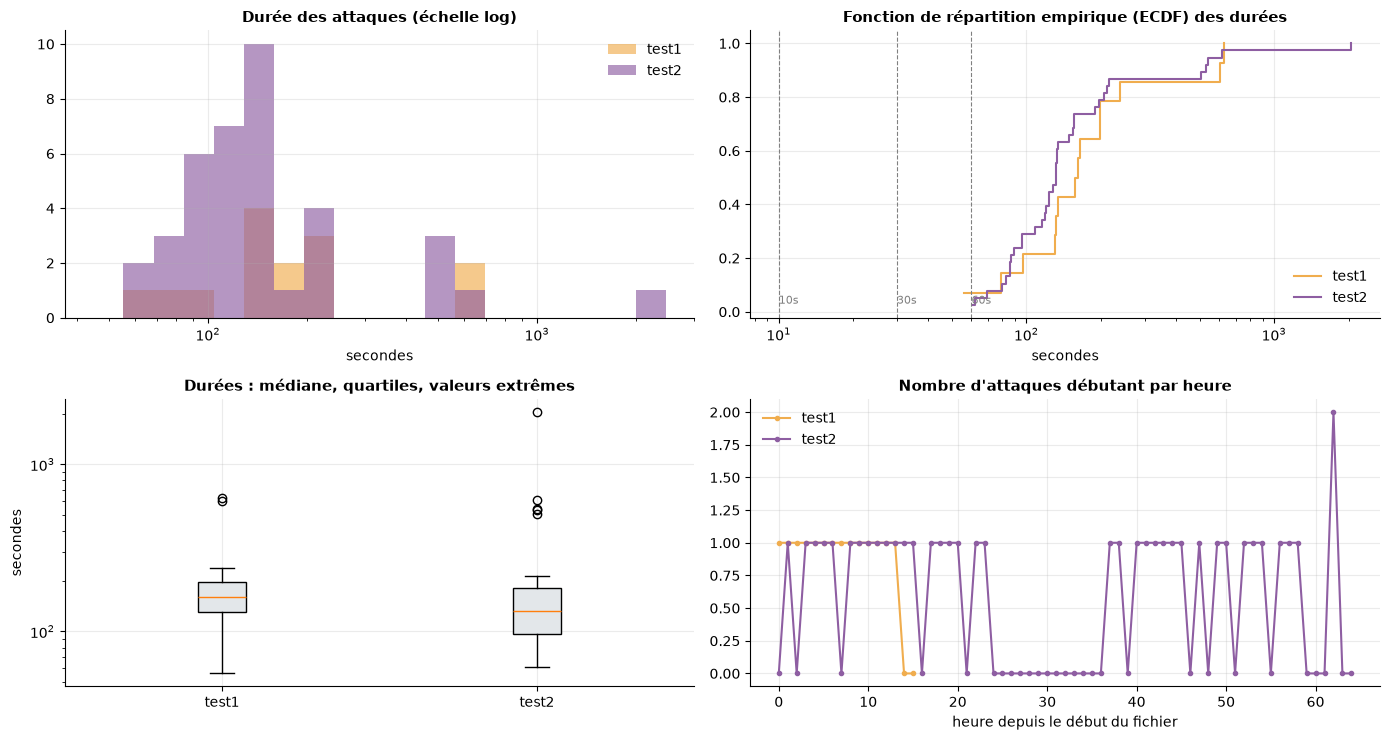

In [21]:

dq = pd.DataFrame({
    k: SEG[k]["durée_s"].describe(
        percentiles=[.1, .25, .5, .75, .9]
    ).round(1)
    for k in SEG
}).T
display(dq)

cov = pd.DataFrame({
    k: TG.duration_coverage(SEG[k]["durée_s"], WINDOWS_S)
    for k in SEG
}).T

cov.columns = [f"≥ {w} s" for w in WINDOWS_S]
display((100 * cov).round(0).astype(int).astype(str) + " %")

freq = pd.DataFrame({
    k: {
        "événements / heure": round(
            len(SEG[k]) / (len(clean[k]) / 3600), 2
        ),
        "délai moyen entre débuts (min)": round(
            np.diff(
                SEG[k]["début"].astype("int64") / 1e9
            ).mean() / 60, 1
        )
    }
    for k in SEG
}).T

display(freq)

fig, ax = plt.subplots(2, 2, figsize=(14, 7.5))
ax = ax.ravel()

bins = np.logspace(
    np.log10(max(1, min(s["durée_s"].min() for s in SEG.values()) * .8)),
    np.log10(max(s["durée_s"].max() for s in SEG.values()) * 1.2),
    20
)

for k in SEG:
    ax[0].hist(
        SEG[k]["durée_s"],
        bins=bins,
        alpha=.65,
        color=PAL[k],
        label=k
    )

ax[0].set_xscale("log")
ax[0].set_title("Durée des attaques (échelle log)")
ax[0].set_xlabel("secondes")
ax[0].legend(frameon=False)

for k in SEG:
    d = np.sort(SEG[k]["durée_s"])
    ax[1].step(
        d,
        np.arange(1, len(d) + 1) / len(d),
        where="post",
        color=PAL[k],
        label=k
    )

for w in (10, 30, 60):
    ax[1].axvline(w, ls="--", c="grey", lw=.8)
    ax[1].text(w, .03, f"{w}s", fontsize=8, color="grey")

ax[1].set_xscale("log")
ax[1].set_title("Fonction de répartition empirique (ECDF) des durées")
ax[1].set_xlabel("secondes")
ax[1].legend(frameon=False)

# Correction Matplotlib : tick_labels au lieu de labels
ax[2].boxplot(
    [SEG[k]["durée_s"] for k in SEG],
    tick_labels=list(SEG),
    vert=True,
    patch_artist=True,
    boxprops=dict(facecolor="#e3e7ea")
)

ax[2].set_yscale("log")
ax[2].set_title("Durées : médiane, quartiles, valeurs extrêmes")
ax[2].set_ylabel("secondes")

for k in SEG:
    h = pd.Series(
        1,
        index=SEG[k]["début"]
    ).resample("1h").sum().reindex(
        pd.date_range(
            clean[k].timestamp.min().floor("h"),
            clean[k].timestamp.max(),
            freq="1h"
        ),
        fill_value=0
    )

    ax[3].plot(
        np.arange(len(h)),
        h.values,
        marker="o",
        ms=3,
        color=PAL[k],
        label=k
    )

ax[3].set_title("Nombre d'attaques débutant par heure")
ax[3].set_xlabel("heure depuis le début du fichier")
ax[3].legend(frameon=False)

savefig("42_duree_frequence")


In [22]:
allm = pd.concat(SEG.values())["durée_s"]
EV["durations"] = {"min": int(allm.min()), "median": float(allm.median()), "max": int(allm.max())}
insight("Durée", f"Durées de {int(allm.min())} s à {int(allm.max())} s (médiane {allm.median():.0f} s). Part des événements au moins aussi longs que la fenêtre : " + "; ".join(f"{w} s → {100*(allm >= w).mean():.0f} %" for w in WINDOWS_S) + ".")
short60, short120 = (allm < 60).mean(), (allm < 120).mean()
insight("Fenêtres", f"{100*short60:.0f} % des attaques durent moins de 60 s et {100*short120:.0f} % moins de 120 s. " + ("Une fenêtre de 60 s dilue déjà une partie des événements ; " if short60 > 0 else "Aucune attaque ne dure moins de 60 s, mais ") + (f"une fenêtre de 120 s en dilue {100*short120:.0f} % et une fenêtre de 300 s {100*(allm < 300).mean():.0f} %. " ) + "Les fenêtres de 10 et 30 s sont les plus sûres pour la détection ; les longues apportent du contexte mais retardent la réaction.")
insight("Réalisme", f"Fréquence : {freq.loc['test1','événements / heure']} attaque/h (test1) et {freq.loc['test2','événements / heure']} attaque/h (test2). Une attaque toutes les 1 à 2 heures est volontairement très supérieure à la réalité d'une usine : le dataset sert à tester la détection, pas à estimer un taux d'incidents réel. Les fausses alertes par heure mesurées ici seront donc plus pénalisantes qu'en exploitation.")

💡 [Durée] Durées de 56 s à 2052 s (médiane 132 s). Part des événements au moins aussi longs que la fenêtre : 10 s → 100 %; 30 s → 100 %; 60 s → 98 %; 120 s → 67 %; 300 s → 13 %.
💡 [Fenêtres] 2 % des attaques durent moins de 60 s et 33 % moins de 120 s. Une fenêtre de 60 s dilue déjà une partie des événements ; une fenêtre de 120 s en dilue 33 % et une fenêtre de 300 s 87 %. Les fenêtres de 10 et 30 s sont les plus sûres pour la détection ; les longues apportent du contexte mais retardent la réaction.
💡 [Réalisme] Fréquence : 0.93 attaque/h (test1) et 0.59 attaque/h (test2). Une attaque toutes les 1 à 2 heures est volontairement très supérieure à la réalité d'une usine : le dataset sert à tester la détection, pas à estimer un taux d'incidents réel. Les fausses alertes par heure mesurées ici seront donc plus pénalisantes qu'en exploitation.


## 32. Distribution temporelle des attaques
**Pourquoi.** Les attaques sont-elles réparties uniformément, regroupées en rafales, ou planifiées à intervalles réguliers ? Cela détermine le risque qu'un modèle apprenne le *calendrier* plutôt que le comportement, et la façon de découper les données en blocs de validation.

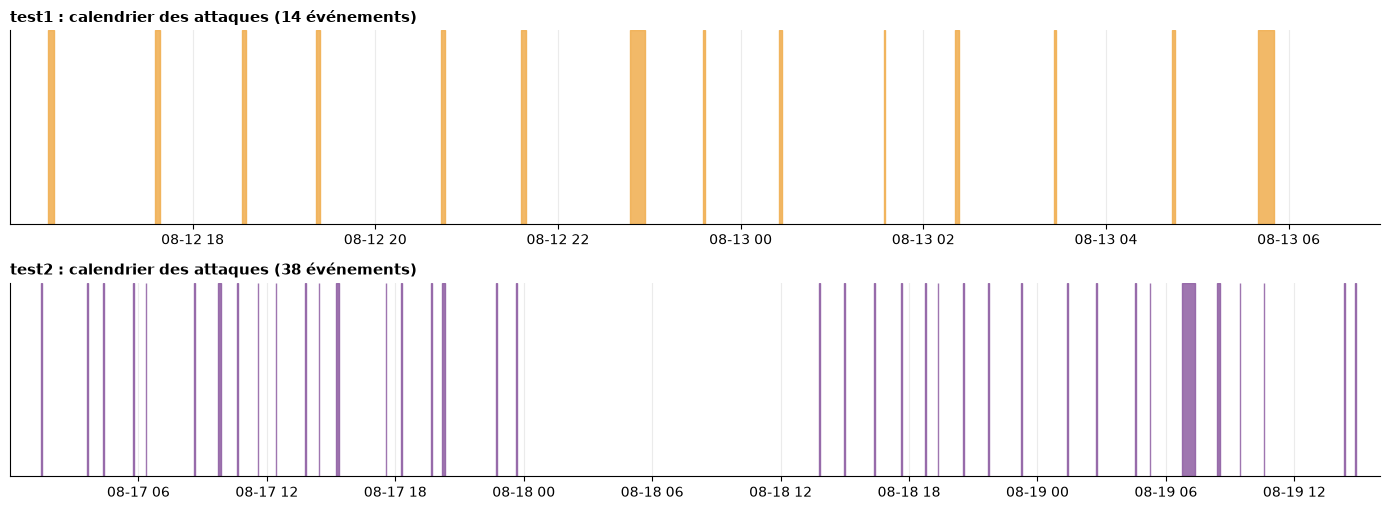

,CV des délais entre débuts,lecture du CV,χ² : uniformité des secondes d'attaque par heure (p),1re attaque après (s),attaques avec < 5 min de normal avant
fichier,,,,,
test1,0.19,régulier,0,1503,0
test2,1.32,par rafales,0,5225,0


In [23]:
fig, ax = plt.subplots(2, 1, figsize=(14, 5.2))
for a, k in zip(ax, SEG):
    t0 = clean[k].timestamp.min()
    for _, s in SEG[k].iterrows(): a.axvspan(s["début"], s["fin"], color=PAL[k], alpha=.85)
    a.set_xlim(t0, clean[k].timestamp.max()); a.set_yticks([]); a.set_title(f"{k} : calendrier des attaques ({len(SEG[k])} événements)", loc="left")
savefig("43_calendrier_attaques")
rows = []
for k in SEG:
    st = SEG[k]["début"].astype("int64") / 1e9; cv = TG.interarrival_cv(st)
    h = pd.Series(clean[k].label.to_numpy(), index=clean[k].timestamp).resample("1h").sum(); chi = stats.chisquare(h.values) if h.sum() > 0 else None
    first = (SEG[k]["début"].iloc[0] - clean[k].timestamp.min()).total_seconds()
    pause = SEG[k]["pause_avant_s"].copy(); pause.iloc[0] = first                       # 1re attaque : temps écoulé depuis le début du fichier
    rows.append({"fichier": k, "CV des délais entre débuts": round(cv, 2), "lecture du CV": "régulier" if cv < .7 else "aléatoire (Poisson ≈ 1)" if cv < 1.3 else "par rafales", "χ² : uniformité des secondes d'attaque par heure (p)": f"{chi.pvalue:.3g}" if chi else "n/a",
                 "1re attaque après (s)": int(first), "attaques avec < 5 min de normal avant": int((pause < PRE_S).sum())})
tm = pd.DataFrame(rows).set_index("fichier"); display(tm)

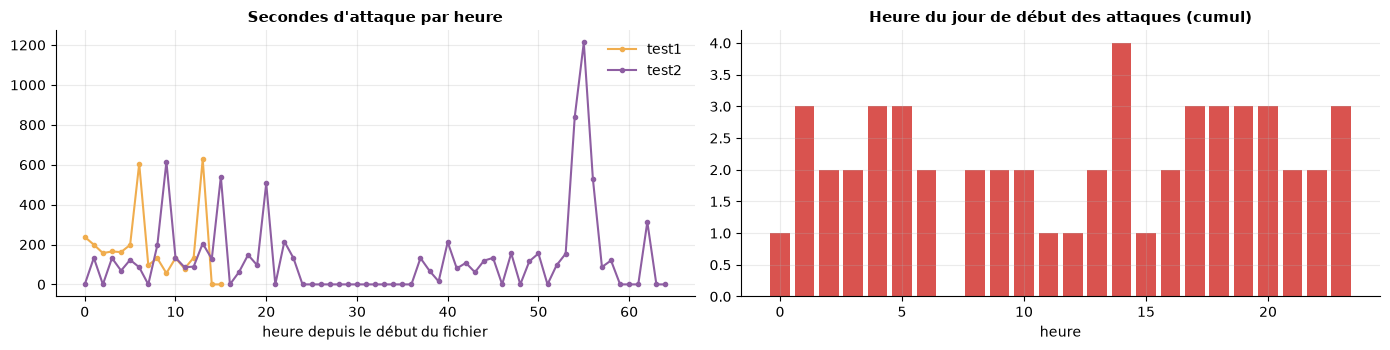

💡 [Calendrier] Régularité des arrivées (CV des délais entre débuts) : test1 = 0.19 (régulier); test2 = 1.32 (par rafales). Un CV éloigné de 1 indique un calendrier d'expérience (planifié) et non des attaques aléatoires : un modèle pourrait exploiter ce calendrier si on lui donnait l'heure comme variable.
💡 [Calendrier] Aucune variable temporelle absolue (heure, jour, rang de la seconde) ne doit entrer dans les features : le calendrier des attaques est un artefact du protocole d'expérience, pas un signal physique.
💡 [Baseline locale] Certaines attaques n'ont pas 5 minutes de fonctionnement normal juste avant elles (début de fichier ou attaque rapprochée de la précédente) : la comparaison « avant / pendant » ne sera pas possible pour toutes (voir tableau).


In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
for k in SEG:
    h = pd.Series(clean[k].label.to_numpy(), index=clean[k].timestamp).resample("1h").sum(); ax[0].plot(np.arange(len(h)), h.values, marker="o", ms=3, color=PAL[k], label=k)
ax[0].set_title("Secondes d'attaque par heure"); ax[0].set_xlabel("heure depuis le début du fichier"); ax[0].legend(frameon=False)
hod = pd.concat([SEG[k]["début"].dt.hour for k in SEG]).value_counts().reindex(range(24), fill_value=0); ax[1].bar(hod.index, hod.values, color=PAL["attack"]); ax[1].set_title("Heure du jour de début des attaques (cumul)"); ax[1].set_xlabel("heure")
savefig("44_attaques_par_heure")
insight("Calendrier", "Régularité des arrivées (CV des délais entre débuts) : " + "; ".join(f"{k} = {tm.loc[k,'CV des délais entre débuts']} ({tm.loc[k,'lecture du CV']})" for k in SEG) + ". Un CV éloigné de 1 indique un calendrier d'expérience (planifié) et non des attaques aléatoires : un modèle pourrait exploiter ce calendrier si on lui donnait l'heure comme variable.")
insight("Calendrier", "Aucune variable temporelle absolue (heure, jour, rang de la seconde) ne doit entrer dans les features : le calendrier des attaques est un artefact du protocole d'expérience, pas un signal physique.")
insight("Baseline locale", "Certaines attaques n'ont pas 5 minutes de fonctionnement normal juste avant elles (début de fichier ou attaque rapprochée de la précédente) : la comparaison « avant / pendant » ne sera pas possible pour toutes (voir tableau).")

## 33. Transitions Normal → Attack → Normal
**Pourquoi.** La cible n'est pas une suite de tirages indépendants : un état persiste. Les **transitions** décrivent cette persistance, et la façon dont le système revient (ou non) à la normale après une attaque conditionne la définition des *fausses alertes* et la marge de détection tardive.

### 33.1 Matrice de transition et durées de séjour

,P(rester normal),P(normal → attaque),P(attaque → normal),P(rester en attaque),durée moyenne d'un séjour normal (s),durée moyenne d'une attaque (s)
test1,0.99973,0.00027,0.00470,0.99530,3644.14286,212.92857
test2,0.99983,0.00017,0.00452,0.99548,5842.00000,221.13158


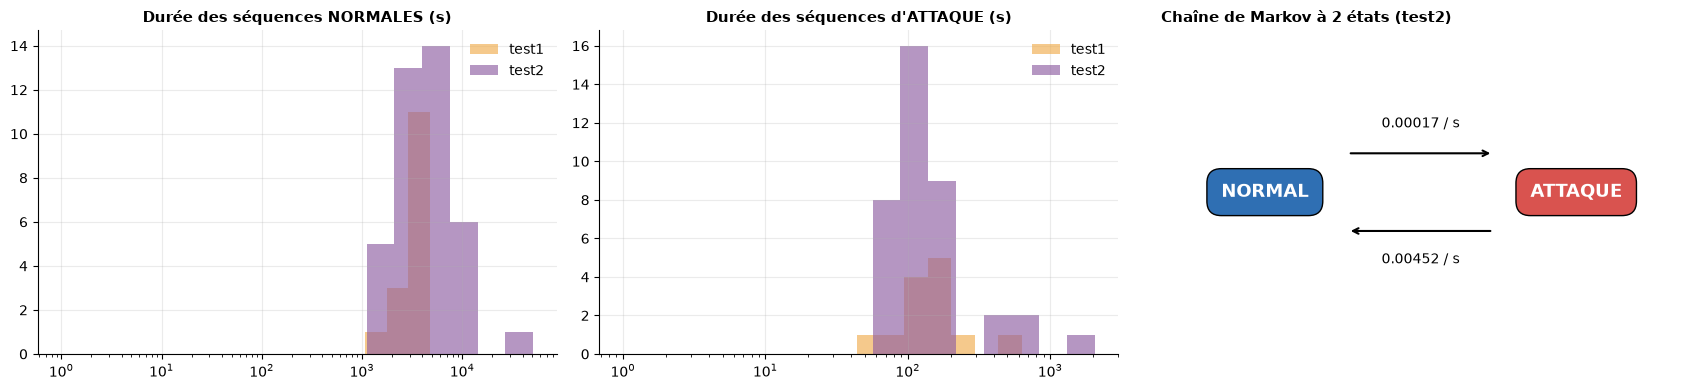

💡 [Transitions] Une fois en attaque, le label reste à 1 la seconde suivante avec une probabilité de 0.9955 (test2) : durée moyenne d'une attaque ≈ 221 s ; une fois normal, il y reste avec une probabilité de 0.99983 : durée moyenne d'un séjour normal ≈ 5842 s. Les labels sont très persistants : une alarme isolée d'une seconde n'a pas de sens ; on raisonne en séquences.


In [25]:
P = {k: TG.transition_matrix(clean[k].label) for k in clean}
tab = pd.DataFrame({k: {"P(rester normal)": P[k][0, 0], "P(normal → attaque)": P[k][0, 1], "P(attaque → normal)": P[k][1, 0], "P(rester en attaque)": P[k][1, 1],
                        "durée moyenne d'un séjour normal (s)": 1 / max(P[k][0, 1], 1e-12), "durée moyenne d'une attaque (s)": 1 / max(P[k][1, 0], 1e-12)} for k in clean}).T; display(tab.round(5))
rl_n = {k: TG.run_lengths(clean[k].label, 0) for k in clean}; rl_a = {k: TG.run_lengths(clean[k].label, 1) for k in clean}
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for k in clean:
    ax[0].hist(rl_n[k], bins=np.logspace(0, np.log10(max(rl_n[k].max(), 10)), 18), alpha=.65, color=PAL[k], label=k)
    ax[1].hist(rl_a[k], bins=np.logspace(0, np.log10(max(rl_a[k].max(), 10)), 18), alpha=.65, color=PAL[k], label=k)
for a, t in zip(ax[:2], ("Durée des séquences NORMALES (s)", "Durée des séquences d'ATTAQUE (s)")): a.set_xscale("log"); a.set_title(t); a.legend(frameon=False)
ax[2].axis("off"); k = "test2"; pn, pa = P[k][0, 1], P[k][1, 0]
for (x, y, t, c) in ((.2, .5, "NORMAL", PAL["normal"]), (.8, .5, "ATTAQUE", PAL["attack"])): ax[2].text(x, y, t, ha="center", va="center", fontsize=13, fontweight="bold", color="white", bbox=dict(boxstyle="round,pad=.8", fc=c))
ax[2].annotate("", xy=(.64, .62), xytext=(.36, .62), arrowprops=dict(arrowstyle="->", lw=1.5)); ax[2].text(.5, .70, f"{pn:.5f} / s", ha="center"); ax[2].annotate("", xy=(.36, .38), xytext=(.64, .38), arrowprops=dict(arrowstyle="->", lw=1.5)); ax[2].text(.5, .28, f"{pa:.5f} / s", ha="center")
ax[2].set_title("Chaîne de Markov à 2 états (test2)", loc="left"); ax[2].set_xlim(0, 1); ax[2].set_ylim(0, 1)
savefig("45_transitions")
insight("Transitions", f"Une fois en attaque, le label reste à 1 la seconde suivante avec une probabilité de {P['test2'][1,1]:.4f} (test2) : durée moyenne d'une attaque ≈ {1/max(P['test2'][1,0],1e-12):.0f} s ; une fois normal, il y reste avec une probabilité de {P['test2'][0,0]:.5f} : durée moyenne d'un séjour normal ≈ {1/max(P['test2'][0,1],1e-12):.0f} s. Les labels sont très persistants : une alarme isolée d'une seconde n'a pas de sens ; on raisonne en séquences.")

### 33.2 Que se passe-t-il physiquement quand le label repasse à 0 ?
Le label passe à 0 à la fin de l'attaque, mais **le procédé peut rester perturbé** un moment (inertie thermique, hydraulique, boucles de régulation). Si c'est le cas, une alarme qui continue après la fin officielle n'est pas une fausse alerte « pour de bon », et la marge de tolérance (`GRACE_S`, 60 s en Phase 2) doit être justifiée.

**Méthode.** Pour chaque attaque, on fixe une baseline sur les 5 minutes normales qui la précèdent (médiane et écart robuste de chaque variable), puis on suit l'**écart** à cette baseline, en unités d'écart robuste (valeur lissée sur 10 s).

*Piège évité.* Une attaque n'affecte que quelques variables (médiane de 3 sur HAI, d'après l'étape 1) : une moyenne ou une médiane sur les 66 variables serait écrasée par les variables non touchées et ne verrait rien. On suit donc, pour chaque événement, les **K = 3 variables les plus perturbées pendant cet événement**. Pour rester équitable, **exactement la même sélection** est appliquée aux fenêtres normales de même durée (placebo) : la comparaison attaque / placebo est alors sans biais de sélection.

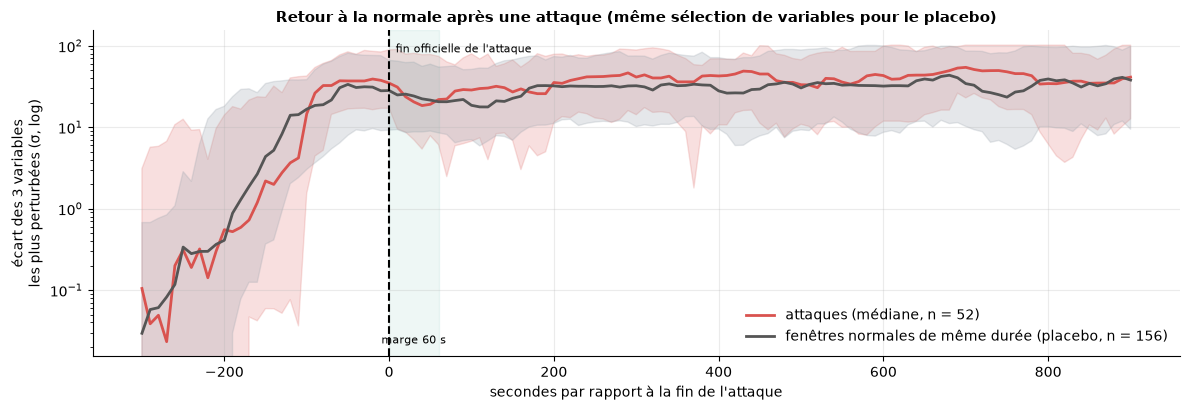

In [27]:
FEATS = {
    k: [c for c in sensor_columns(clean[k]) if clean[k][c].std() > 0]
    for k in clean
}

OFFS = np.arange(-300, 901, 10)
WIN = 10

def baseline(X, lab, i0):
    idx = np.arange(max(0, i0 - PRE_S), i0)
    idx = idx[lab[idx] == 0]

    if len(idx) < 60:
        return None

    med = np.median(X[idx], axis=0)
    return med, 1.4826 * np.median(np.abs(X[idx] - med), axis=0)


K_TOP = 3

def dev(X, t, med, scale, cols):
    return float(
        np.median(
            np.abs(
                np.median(X[t - WIN + 1:t + 1][:, cols], axis=0) - med[cols]
            ) / scale[cols]
        )
    )


def curve(X, lab, i0, i1, floor):
    b = baseline(X, lab, i0)

    if b is None:
        return None

    med, scale = b[0], np.maximum(b[1], floor)
    n = len(X)
    row = np.full(len(OFFS), np.nan)

    # Variables les plus perturbées pendant l'événement
    cols = np.argsort(
        np.median(np.abs(X[i0:i1 + 1] - med) / scale, axis=0)
    )[-K_TOP:]

    for a, off in enumerate(OFFS):
        t = i1 + off

        if t - WIN + 1 < 0 or t >= n:
            continue

        if off > 0 and lab[t - WIN + 1:t + 1].any():
            continue

        row[a] = dev(X, t, med, scale, cols)

    return row


rng = np.random.default_rng(SEED)
A, PL = [], []

for k in clean:
    df = clean[k]
    X = df[FEATS[k]].to_numpy("float64")
    lab = df.label.to_numpy()
    n = len(X)
    floor = 0.02 * X.std(axis=0)
    cs = np.r_[0, np.cumsum(lab)]

    for _, s in SEG[k].iterrows():
        i0, i1 = int(s.i0), int(s.i1)
        r = curve(X, lab, i0, i1, floor)

        if r is None:
            continue

        A.append(r)

        d = i1 - i0 + 1
        got = tries = 0

        while got < 3 and tries < 300:
            tries += 1

            a0 = int(
                rng.integers(
                    PRE_S,
                    max(PRE_S + 1, n - d - 910)
                )
            )

            if (
                a0 + d + 900 < n
                and cs[a0 + d + 901] - cs[a0 - PRE_S] == 0
            ):
                p = curve(X, lab, a0, a0 + d - 1, floor)

                if p is not None:
                    PL.append(p)
                    got += 1


A = np.array(A)
PL = np.array(PL)

am = np.nanmedian(A, axis=0)
a25 = np.nanpercentile(A, 25, axis=0)
a75 = np.nanpercentile(A, 75, axis=0)

pm = np.nanmedian(PL, axis=0)
p25 = np.nanpercentile(PL, 25, axis=0)
p75 = np.nanpercentile(PL, 75, axis=0)


fig, ax = plt.subplots(figsize=(12, 4.2))

ax.fill_between(
    OFFS, a25, a75,
    color=PAL["attack"], alpha=.18
)

ax.plot(
    OFFS, am,
    color=PAL["attack"],
    lw=2,
    label=f"attaques (médiane, n = {len(A)})"
)

ax.fill_between(
    OFFS, p25, p75,
    color=PAL["grey"], alpha=.25
)

ax.plot(
    OFFS, pm,
    color="#555",
    lw=2,
    label=f"fenêtres normales de même durée (placebo, n = {len(PL)})"
)

ax.axvline(0, c="k", ls="--")
ax.axvspan(0, 60, color=PAL["ok"], alpha=.1)

tr = ax.get_xaxis_transform()

ax.text(
    8, .96, "fin officielle de l'attaque",
    fontsize=8, transform=tr, va="top"
)

ax.text(
    30, .04, "marge 60 s",
    fontsize=8, ha="center", transform=tr
)

ax.set_yscale("log")
ax.set_xlabel("secondes par rapport à la fin de l'attaque")

# Correction de l'erreur SyntaxError
ax.set_ylabel(
    f"écart des {K_TOP} variables\nles plus perturbées (σ, log)"
)

ax.legend(frameon=False)

ax.set_title(
    "Retour à la normale après une attaque "
    "(même sélection de variables pour le placebo)"
)

savefig("46_retour_normale")

In [28]:
pos = OFFS >= 0; rec = None
for i in np.flatnonzero(pos):
    if np.all(am[i:][np.isfinite(am[i:])] <= p75[i:][np.isfinite(am[i:])]): rec = int(OFFS[i]); break
ratio0 = am[OFFS == 0][0] / max(pm[OFFS == 0][0], 1e-9); EV["recovery_s"] = rec
insight("Retour au normal", f"À la fin officielle de l'attaque, l'écart des variables les plus perturbées vaut {ratio0:.1f} × celui des fenêtres normales de même durée. " + (f"Il redevient durablement compatible avec la fluctuation normale (sous le 3ᵉ quartile du placebo, mêmes règles de sélection) à partir de ≈ {rec} s après la fin." if rec is not None else "Il ne redevient pas compatible avec la fluctuation normale dans les 900 s observées : le procédé reste perturbé bien après la fin du label."))
insight("Marge de tolérance", (f"La marge de 60 s de la Phase 2 est {'cohérente avec' if rec is not None and rec <= 60 else 'INSUFFISANTE au regard de'} ce délai de retour ({rec} s)." if rec is not None else "La marge de 60 s est insuffisante : une alarme prolongée après la fin d'une attaque est un effet physique, pas une fausse alerte. À discuter dans le protocole d'évaluation.") + " Indicatif : estimation sur un nombre limité d'événements, avec des variables de natures très différentes.")

💡 [Retour au normal] À la fin officielle de l'attaque, l'écart des variables les plus perturbées vaut 1.2 × celui des fenêtres normales de même durée. Il redevient durablement compatible avec la fluctuation normale (sous le 3ᵉ quartile du placebo, mêmes règles de sélection) à partir de ≈ 0 s après la fin.
💡 [Marge de tolérance] La marge de 60 s de la Phase 2 est cohérente avec ce délai de retour (0 s). Indicatif : estimation sur un nombre limité d'événements, avec des variables de natures très différentes.


## Synthèse de la Partie 4

In [29]:
from collections import defaultdict
by = defaultdict(list)
for t, m in FINDINGS: by[t].append(m)
for t, ms in by.items():
    print(f"\n■ {t}")
    for m in ms: print("   •", m)
json.dump({"findings": FINDINGS, "key_numbers": EV}, open(REPORT_DIR / "target_analysis.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False, default=str)
print(f"\n{len(FINDINGS)} constats → reports/target_analysis.json ; événements → reports/attack_events.csv")


■ Cible
   • La cible est binaire (0 normal / 1 attaque), à 1 Hz, sans valeur manquante, et n'existe que dans test1 et test2.
   • label-test2.csv a 230,400 lignes mais seulement 3,841 timestamps distincts (60 lignes par timestamp) : ses dates sont TRONQUÉES À LA MINUTE. Une jointure sur le timestamp est donc fausse ; l'alignement correct est « positionnel » (même nombre de lignes que les mesures, concordance à la minute vérifiée à 100 %). Ces « doublons » apparents ne sont pas une erreur de données.

■ Répartition
   • test1 : 5.52 % d'attaque ; test2 : 3.65 %. Sur l'ensemble des 1,180,800 secondes du dataset, seulement 0.96 % sont des attaques : la classe d'intérêt est très rare.

■ Déséquilibre
   • Rapport normal : attaque = 17 : 1 (test1) et 26 : 1 (test2). Un détecteur qui ne signale JAMAIS d'attaque obtient une accuracy de 94.5 % et 96.4 % avec un rappel nul : l'accuracy est inutilisable.
   • Un score aléatoire obtient une précision moyenne ≈ p (0.055 et 0.036) et une AUC de 0

### Ce que la Partie 4 impose à la suite du projet
| Constat | Conséquence |
|---|---|
| Cible binaire, présente seulement dans test1 et test2 | apprentissage non supervisé ; labels pour régler le seuil et évaluer |
| Moins de 1 % du dataset en attaque ; 5,5 % et 3,7 % des fichiers de test | pas d'accuracy ; précision moyenne et F1 comparés à la valeur plancher (≈ p) |
| 52 événements, quelques-uns très longs | métriques par événement (eTaPR, rappel par attaque) ; intervalle de confiance indispensable |
| Durées de ~1 à 34 min | fenêtres de 10 et 30 s privilégiées ; 120 et 300 s diluent la plupart des attaques |
| Calendrier d'expérience (arrivées régulières) | aucune variable temporelle absolue dans les features |
| Labels très persistants ; procédé encore perturbé après la fin du label | raisonner en séquences ; marge de tolérance à justifier avec la mesure du §33.2 |
| Alignement de `label-test2` vérifié à la seconde | confiance dans la vérité terrain (limite : en-tête officiel incohérent avec la liste) |

**Suite du plan :** Partie 7 (*Temporal Data Drift*), qui utilise ces événements pour comparer le drift normal au changement associé aux attaques.